# ML Zoomcamp 2026 — Homework 4

Official: `materials/homework.md` (do not edit).
Data: `data/course_lead_scoring_2026.csv` (2026 pinned lead-scoring release).
Write-up: `ML_04_HW.md`.
Gemini drafts: `GEMINI_Q_DRAFTS.md`.

Kernel: **ML Zoomcamp** / this folder `.venv`. Do not use `!pip` / `!wget`.
Split seed is **1**, not 42.


## 0) Imports


In [1]:
import os
# import os: load the standard library for operating-system features.
# At this point: cache, temp, and thread settings go into environment variables, not file paths.

os.environ.setdefault(r"MPLCONFIGDIR", r"E:\IT_SPACES\AI\.cache\matplotlib")
# os.environ: the environment-variable dict this Python process sees.
# .setdefault(key, value): set the value only when the key is missing. Leave an existing value alone.
# First argument "MPLCONFIGDIR": the folder name Matplotlib uses for its config files.
# Second argument E:...matplotlib: point that folder at the E: cache, not C:.
# At this point: stop Matplotlib from writing under C:\Users\... and hitting permission or disk limits.

os.environ.setdefault(r"XDG_CACHE_HOME", r"E:\IT_SPACES\AI\.cache")
# .setdefault: same method as above. Only the key changes.
# "XDG_CACHE_HOME": the standard root many libraries use for caches.
# At this point: put the shared cache on E:\IT_SPACES\AI\.cache.

os.environ.setdefault(r"TEMP", r"E:\IT_SPACES\AI\.cache\tmp")
# "TEMP": the Windows variable for temporary files.
# At this point: send temp files to the E: tmp folder as well.

os.environ.setdefault(r"TMP", r"E:\IT_SPACES\AI\.cache\tmp")
# "TMP": the pair of TEMP. Some programs read TMP instead of TEMP.
# At this point: both variables point at the same E: tmp folder.

os.environ.setdefault("OMP_NUM_THREADS", "1")
# "OMP_NUM_THREADS": how many threads OpenMP may use.
# "1": use a single thread.
# At this point: keep one library from grabbing every CPU core.

os.environ.setdefault("MKL_NUM_THREADS", "1")
# "MKL_NUM_THREADS": thread count for Intel MKL.
# At this point: stop the MKL build behind numpy/sklearn from running away with many threads.

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
# "OPENBLAS_NUM_THREADS": thread count for OpenBLAS.
# At this point: if the BLAS backend is OpenBLAS, keep it at one thread too.

os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")
# "NUMEXPR_NUM_THREADS": thread count for NumExpr.
# At this point: if pandas or numpy uses NumExpr, that path stays at one thread as well.

import numpy as np
# import numpy: load the numeric-array library.
# as np: later code uses the short name np instead of numpy.
# At this point: needed for .values arrays and for negating a score when AUC is below 0.5.

import pandas as pd
# import pandas: load the table (DataFrame) library.
# as pd: call pandas pd.
# At this point: needed to read the CSV, select columns, and fill missing values.

import matplotlib.pyplot as plt
# import matplotlib.pyplot: the plotting module.
# as plt: short name.
# At this point: Q1 does not call it. Q3 uses it for the precision and recall curves.

from sklearn.model_selection import train_test_split, KFold
# from sklearn.model_selection: the module that splits rows.
# import train_test_split: randomly split a table into two pieces.
# import KFold: split the same table into folds for cross-validation.
# At this point: train_test_split is used in the official split below. KFold is for Q5 and Q6, not Q1.

from sklearn.metrics import roc_auc_score, precision_score, recall_score
# from sklearn.metrics: the module of evaluation functions.
# import roc_auc_score: AUC — how well a score ranks positives above negatives.
# import precision_score: share of predicted positives that are truly positive. Not called in Q1.
# import recall_score: share of true positives that were found. Not called in Q1.
# At this point: the Q1 calculation uses roc_auc_score only.

from sklearn.feature_extraction import DictVectorizer
# from sklearn.feature_extraction: tools that turn raw rows into numeric model input.
# import DictVectorizer: class that one-hot encodes a list of dicts.
# At this point: not called in Q1. Used for one-hot encoding in Q2.

from sklearn.linear_model import LogisticRegression
# from sklearn.linear_model: linear classifiers and regressors.
# import LogisticRegression: the logistic-regression classifier class.
# At this point: Q1 does not fit a model. Used from Q2 onward.

## 1) Load data


In [2]:
df = pd.read_csv("data/course_lead_scoring_2026.csv")
# pd: pandas, imported above as pd.
# .read_csv(path): read that CSV file into a DataFrame.
# "data/course_lead_scoring_2026.csv": the local file in the homework folder. Not an internet wget.
# df = : store the table under the name df so later cells can reuse it.
# At this point: load the pinned 2026 lead-scoring table into memory.

df.head()
# df: the table just read.
# .head(): by default, show the first 5 rows.
# At this point: check column names, the converted target (0/1), and whether missing cells show up.

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Data preparation

If missing values are present: categorical -> `'NA'`, numerical -> `0.0`.


In [3]:
df.isnull().sum()
# df: the raw table.
# .isnull(): a same-shaped table of True where a cell is missing and False where it has a value.
# .sum(): count True as 1 and collapse each column into one missing-count. Default axis is columns, not rows.
# At this point: the homework asks whether missing values are present. If annual_income or lead_score has blanks, fill them before the Q1 AUC.

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categorical_cols = df.select_dtypes(include=['object', 'string']).columns
# df.select_dtypes(...): return a view that keeps only the requested dtypes. Rows stay; columns are filtered.
# include=['object', 'string']: the dtypes to keep. String / categorical columns.
# .columns: take only the column names of that view (an Index).
# categorical_cols = : store the list of categorical column names.
# At this point: collect the names that will be filled with 'NA'.

df[categorical_cols] = df[categorical_cols].fillna('NA')
# df[categorical_cols]: select only the categorical columns.
# .fillna('NA'): return a new frame where blanks in that view are the string 'NA'. It does not edit the original by itself.
# Left-hand df[categorical_cols] = : write the filled columns back into those positions in df.
# At this point: turn categorical missing values into a real category so later encoding does not die on blanks.

numerical_cols = df.select_dtypes(include=['number']).columns
# select_dtypes: the same method again. This include is numeric.
# include=['number']: int/float and other numeric columns.
# .columns: the numeric column names.
# At this point: collect the names that will be filled with 0.0. converted is numeric too, but this CSV has zero missing values in converted.

df[numerical_cols] = df[numerical_cols].fillna(0.0)
# df[numerical_cols]: select only the numeric columns.
# .fillna(0.0): fill blanks with the float 0.0.
# Left-hand assignment: write the filled numeric columns back into df.
# At this point: fill blanks in annual_income and lead_score so roc_auc_score in Q1 does not fail on NaN.

## Split the data

Use these exact calls. `converted` must not stay in the feature dataframes.
`random_state=1` (not 42).


In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
# train_test_split: randomly split rows into two pieces. The first return is the larger piece; the second is the held-out piece.
# First argument df: the full table to split. It must already have missing values filled.
# test_size=0.2: the second piece (df_test) is 20%. The first piece (df_full_train) is the remaining 80%.
# random_state=1: freeze the shuffle with seed 1. This is not HW3's 42. The homework text uses this seed.
# df_full_train, df_test = : name the 80% and the 20%.
# At this point: lock the final test set away. The remaining 80% is for train, validation, and the Q5/Q6 cross-validation.

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
# train_test_split: call the same function again. Split the already separated 80%.
# First argument df_full_train: the 80% table after test was removed.
# test_size=0.25: 25% of this 80% is 20% of the full data. The first piece is 60% of the full data.
# random_state=1: this shuffle also uses seed 1. It must match the second line of the homework text.
# df_train, df_val = : 60% train, 20% validation.
# At this point: Q1 uses df_train only. Scoring AUC on df_val or df_test is not question 1.

## Q1 — ROC AUC feature importance

Which numerical variable has the highest AUC? Training set only.
If AUC < 0.5, negate the feature.

- `lead_score`
- `number_of_courses_viewed`
- `interaction_count`
- `annual_income`


In [6]:
numerical_variables = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income',
]
# A list [...]: an ordered box of names.
# The four strings: the same column names as the submission options.
# numerical_variables = : a name the loop can pull from.
# At this point: score only these four options. Adding other numeric columns changes the question.

y_train = df_train['converted'].values
# df_train: the 60% training table.
# ['converted']: the single target column, as a Series.
# .values: turn the pandas Series into a numpy array. sklearn functions accept this shape well.
# y_train = : the name of the label array.
# At this point: prepare the AUC ground truth (whether the lead converted). This step does not train a model.

for col in numerical_variables:
    # for col in ...: take one name at a time into col and repeat the body.
    # At this point: score each of the four columns on its own, with no model, using the raw values as the score.

    score = df_train[col].values
    # df_train[col]: the one numeric column currently under review. col is the string name.
    # .values: turn that column into a numpy array.
    # score = : "treat these numbers as the prediction score."
    # At this point: this is not logistic regression predict_proba. It is the raw column.

    auc = roc_auc_score(y_train, score)
    # roc_auc_score: compute the area under the ROC curve (AUC).
    # First argument y_train: the 0/1 labels.
    # Second argument score: a score that is assumed to rank higher toward the positive class.
    # auc = : a number between 0 and 1. 0.5 is a coin flip.
    # At this point: measure how well this one column ranks converted vs not converted.

    if auc < 0.5:
        # if: run the block below only when the condition is true.
        # auc < 0.5: larger values lean toward the negative class (negative association).
        # At this point: the homework says to flip the direction when AUC is below 0.5.

        auc = roc_auc_score(y_train, -score)
        # -score: negate every value in the array. Large values become small.
        # roc_auc_score(...): call the same function again on the flipped score.
        # At this point: same idea as the homework example -df_train['balance']. Turn an inverse ranking into a direct one so the AUCs can be compared above 0.5.

        print(f"{col}: {auc:.3f} (inverted)")
        # print: write one line to the output.
        # f"...": build a string by filling the braces with values.
        # {col}: the current column name.
        # {auc:.3f}: AUC as a 3-decimal string. This print is for comparison. It is a different question from Q2's "round to 3 digits and submit."
        # (inverted): mark that the score was flipped and recomputed.
        # At this point: leave a readable AUC for the flipped variable.
    else:
        print(f"{col}: {auc:.3f}")
        # else: when the if above is false, that is, the original AUC is at least 0.5.
        # print / f-string / {col} / {auc:.3f}: the same function and syntax as above. There is no "inverted" mark.
        # At this point: print the AUC of a variable that does not need a direction fix.
# After the four lines, pick the variable name with the largest number on the form.

lead_score: 0.788
number_of_courses_viewed: 0.723
interaction_count: 0.765
annual_income: 0.608


## Q2 — Logistic regression AUC (validation)

`LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
DictVectorizer one-hot encoding. AUC on validation, round to 3 digits.

- 0.532
- 0.632
- 0.732
- 0.832


In [7]:
y_train = df_train['converted'].values
# df_train: the 60% training table.
# ['converted']: the target series, whether the lead converted.
# .values: turn the pandas Series into a 1-d numpy array that sklearn handles well.
# y_train = : name of the training label array.
# At this point: lock the training ground-truth labels that validation will be compared against.

y_val = df_val['converted'].values
# df_val: the 20% validation table.
# ['converted']: the validation target column.
# .values: convert to a numpy array.
# y_val = : name of the validation label array.
# At this point: prepare the labels used to score a set the model has not trained on.

X_train = df_train.drop(columns=['converted'])
# df_train: the full training table.
# .drop(columns=['converted']): remove the label column from the feature data.
# X_train = : the training feature table with the label gone.
# At this point: keep only the columns the model is allowed to learn from.

X_val = df_val.drop(columns=['converted'])
# df_val: the full validation table.
# .drop(columns=['converted']): remove the label column from the validation table too.
# X_val = : the validation feature table with the label gone.
# At this point: prepare validation inputs that are used only for the final score, not for fitting.

train_dicts = X_train.to_dict(orient='records')
# X_train: the training feature table without the label.
# .to_dict(): turn the DataFrame into Python dicts.
# orient='records': one dict per row, shaped as {column: value}, collected in a list.
# train_dicts = : name of that list of dicts.
# At this point: pack each row so sklearn can read it and split categories into columns.

val_dicts = X_val.to_dict(orient='records')
# X_val: the validation feature table without the label.
# .to_dict(): turn the DataFrame into dicts.
# orient='records': a list of one dict per row.
# val_dicts = : name of the validation dict list.
# At this point: put the validation rows into the same shape so they can be encoded.

dv = DictVectorizer(sparse=False)
# DictVectorizer: class that turns string categories into 0/1 columns (one-hot encoding).
# sparse=False: return a dense 2-d numpy array instead of a memory-efficient sparse matrix.
# dv = : name of the encoder object.
# At this point: prepare the tool that will learn the encoding rules and apply them.

X_train = dv.fit_transform(train_dicts)
# dv: the DictVectorizer created above.
# .fit_transform(): look at the training dicts to learn which categories exist (fit) and convert them to a 0/1 numeric matrix at the same time (transform).
# X_train = : the 2-d numeric training array the model can take directly.
# At this point: strings are gone and the training matrix is ready.

X_val = dv.transform(val_dicts)
# dv: the encoder whose rules were already fit on train.
# .transform(): encode validation with those same rules. Do not fit on validation.
# X_val = : the numeric validation matrix.
# At this point: validation input has the same columns and width as the training matrix.

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
# LogisticRegression: the linear model class for binary classification.
# solver='liblinear': optimizer that converges steadily on a small dataset.
# C=1.0: inverse of regularization strength. This is the homework's value.
# max_iter=1000: allow up to 1000 optimization steps so the fit does not stop with a convergence warning.
# model = : name of the model object. The homework snippet does not pass random_state.
# At this point: build an unfitted model with the homework's training rules.

model.fit(X_train, y_train)
# model: the prepared logistic regression.
# .fit(): learn the relationship between the feature matrix X_train and the labels y_train.
# At this point: the model finishes adjusting its weights on the training patterns.

y_pred_proba = model.predict_proba(X_val)[:, 1]
# model: the fitted model.
# .predict_proba(X_val): for each validation row, return [probability of 0, probability of 1].
# [:, 1]: keep only the positive-class column (converted = 1).
# y_pred_proba = : 1-d array of positive-class probabilities.
# At this point: keep a score of "how likely is conversion," not a hard 0/1 cut.

val_auc = roc_auc_score(y_val, y_pred_proba)
# roc_auc_score: compare the true labels with the predicted probabilities and return the AUC.
# First argument y_val: validation labels (0 or 1).
# Second argument y_pred_proba: the model's positive-class scores.
# val_auc = : the AUC, a number between 0 and 1.
# At this point: measure how well the model ranks validation leads.
# Do not swap the argument order.

print(f"{val_auc:.3f}")
# print: write the result to the output.
# f"...": formatting syntax that inserts a value into a string.
# {val_auc:.3f}: round the AUC to three decimal places.
# At this point: read the validation score against the form options 0.532 / 0.632 / 0.732 / 0.832.

0.732


## Q3 — Precision and recall intersection

Thresholds 0.0 to 1.0 step 0.01. Ignore both-zero. Smallest |P-R|.

- 0.43
- 0.63
- 0.73
- 0.83


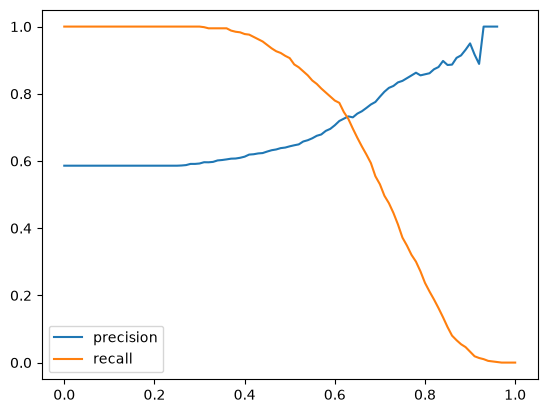

0.63


In [8]:
thresholds = np.linspace(0, 1, 101)
# np.linspace: build evenly spaced numbers.
# Purpose: cut the range from 0 to 1 into 101 points so the step is 0.01.
# Argument 0: start of the threshold search.
# Argument 1: end of the threshold search.
# Argument 101: how many values to create (0.00 through 1.00 by 0.01).
# thresholds = : store that array of candidate thresholds.
# At this point: collect a fine grid of cutoffs so the curves can be compared point by point.

scores = []
# An empty Python list.
# Purpose: a place to store the confusion counts for every threshold.
# scores = : name of that list.
# At this point: collect one row of counts for each of the 101 thresholds.

for t in thresholds:
    # for: walk the sequence one element at a time.
    # Purpose: repeat the confusion-matrix counts for every threshold.
    # thresholds: the array from 0.0 to 1.0 built above.
    # t: the threshold number for this pass.
    # At this point: evaluate every cutoff, one at a time.

    actual_positive = (y_val == 1)
    # y_val == 1: boolean comparison.
    # Purpose: mark validation rows whose true label is converted (1).
    # actual_positive = : name of that True/False mask.
    # At this point: fix the set of true positives that precision and recall are measured against.

    actual_negative = (y_val == 0)
    # y_val == 0: boolean comparison.
    # Purpose: mark validation rows whose true label is not converted (0).
    # actual_negative = : name of that mask.
    # At this point: prepare the set used to count false positives.

    predict_positive = (y_pred_proba >= t)
    # y_pred_proba >= t: boolean comparison.
    # Purpose: call a row positive when its predicted probability is at least the current threshold t.
    # predict_positive = : name of the predicted-positive mask.
    # At this point: see which leads the model flags at this cutoff.

    predict_negative = (y_pred_proba < t)
    # y_pred_proba < t: boolean comparison.
    # Purpose: call a row negative when its predicted probability is below t.
    # predict_negative = : name of the predicted-negative mask.
    # At this point: see which leads the model rejects at this cutoff.

    tp = (predict_positive & actual_positive).sum()
    # predict_positive & actual_positive: element-wise AND.
    # Purpose: keep rows that are predicted positive and truly positive.
    # .sum(): count the True values. That count is true positives (TP).
    # tp = : name of the TP count.
    # At this point: count how many conversions the model caught.

    fp = (predict_positive & actual_negative).sum()
    # predict_positive & actual_negative: element-wise AND.
    # Purpose: keep rows predicted positive that are actually negative.
    # .sum(): count those rows. That count is false positives (FP).
    # fp = : name of the FP count.
    # At this point: count the false alarms.

    fn = (predict_negative & actual_positive).sum()
    # predict_negative & actual_positive: element-wise AND.
    # Purpose: keep rows predicted negative that are actually positive.
    # .sum(): count those rows. That count is false negatives (FN).
    # fn = : name of the FN count.
    # At this point: count the conversions the model missed.

    scores.append((t, tp, fp, fn))
    # scores.append: add one item to the end of the list.
    # Purpose: record this threshold together with its TP, FP, and FN.
    # At this point: keep every threshold's counts so none are dropped when the loop ends.

columns = ['threshold', 'tp', 'fp', 'fn']
# A Python list of strings.
# Purpose: column names for the DataFrame built next.

df_scores = pd.DataFrame(scores, columns=columns)
# pd.DataFrame: build a table.
# Purpose: turn the list of tuples into a DataFrame that is easy to compute on.
# df_scores = : name of that table.
# At this point: lift the per-threshold counts into table operations.

df_scores['precision'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fp'])
# df_scores['precision']: the new column that will hold precision.
# tp / (tp + fp): precision, the share of predicted positives that are truly positive.
# When tp + fp is 0, this division is NaN. Those rows are filtered below.

df_scores['recall'] = df_scores['tp'] / (df_scores['tp'] + df_scores['fn'])
# df_scores['recall']: the new column that will hold recall.
# tp / (tp + fn): recall, the share of true positives that the model found.

plt.plot(df_scores['threshold'], df_scores['precision'], label='precision')
# plt.plot: draw a line.
# Purpose: threshold on the x-axis, precision on the y-axis.
# df_scores['threshold']: x values.
# df_scores['precision']: y values.
# label='precision': name shown in the legend.
# At this point: show how precision moves as the cutoff changes.

plt.plot(df_scores['threshold'], df_scores['recall'], label='recall')
# plt.plot: draw a second line on the same axes.
# Purpose: threshold on the x-axis, recall on the y-axis.
# df_scores['threshold']: x values.
# df_scores['recall']: y values.
# label='recall': legend name.
# At this point: compare where the precision and recall lines cross.

plt.legend()
# plt.legend: draw the legend box.
# Purpose: label which line is precision and which is recall.
# At this point: make the figure readable.

plt.show()
# plt.show: display the finished figure.
# At this point: look at both curves before picking the numeric intersection.

df_filtered = df_scores[
    (df_scores['tp'] + df_scores['fp'] > 0) & 
    ~((df_scores['precision'] == 0) & (df_scores['recall'] == 0))
]
# Boolean filter on df_scores.
# Purpose: drop rows where precision is undefined, and drop rows where both precision and recall are the number 0.
# (tp + fp > 0): the precision denominator is not zero, so precision is not NaN.
# ~((precision == 0) & (recall == 0)): exclude rows where both metrics are exactly 0.
# df_filtered = : the table of rows that are allowed into the comparison.
# At this point: |0 - 0| is 0, so an unfiltered idxmin would treat a both-zero row as the intersection. That row is not a crossing. Precision NaN (0/0, often a very high threshold) is a different case and is already removed by tp + fp > 0.

diff = abs(df_filtered['precision'] - df_filtered['recall'])
# abs: drop the sign.
# Purpose: distance between precision and recall, not which one is larger.
# precision - recall: the signed gap on the filtered rows.
# diff = : the series of absolute gaps.
# At this point: measure how close the two metrics are.

best_row = df_filtered.loc[diff.idxmin()]
# df_filtered.loc: select a row by index label.
# diff.idxmin: index of the smallest absolute gap. idxmin skips NaN, but those rows are already filtered.
# best_row = : the row where precision and recall are closest.
# At this point: identify the threshold the form is asking for.

print(best_row['threshold'])
# print: write the value to the output.
# best_row['threshold']: the cutoff on that closest row.
# At this point: read the precision/recall intersection threshold.

## Q4 — Max F1 threshold

F1 = 2 * P * R / (P + R). Same threshold grid.

- 0.21
- 0.41
- 0.61
- 0.81


In [9]:
# Q4: F1 vs threshold

df_scores['f1'] = 2 * df_scores['precision'] * df_scores['recall'] / (df_scores['precision'] + df_scores['recall'])
# df_scores['f1']: the new column that will hold F1.
# 2 * precision * recall / (precision + recall): the F1 formula, the harmonic mean of precision and recall.
# At this point: score each threshold by how it balances false alarms (precision) and misses (recall).
# When precision + recall is 0, this division is NaN. idxmax below skips NaN, so the Q3 both-zero filter is not required again.

df_scores.loc[df_scores['f1'].idxmax()]
# df_scores.loc: select one row by index label.
# df_scores['f1'].idxmax: index of the largest F1. NaN positions are skipped.
# At this point: show the row whose threshold maximizes F1. The form asks for that threshold, not the F1 number.
# The options are 0.21, 0.41, 0.61, and 0.81.

threshold      0.410000
tp           572.000000
fp           352.000000
fn            14.000000
precision      0.619048
recall         0.976109
f1             0.757616
Name: 41, dtype: float64

## Q5 — 5-fold CV std

`KFold(n_splits=5, shuffle=True, random_state=1)` on `df_full_train`.
Std of validation AUCs.

- 0.001
- 0.007
- 0.013
- 0.060


In [10]:
# Q5: KFold AUC standard deviation

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
# KFold: build a cross-validation splitter.
# Purpose: prepare to cut the data into 5 folds.
# n_splits=5: five pieces.
# shuffle=True: shuffle rows before the split.
# random_state=1: freeze the shuffle so every run uses the same folds.
# kfold = : name of the splitter.
# At this point: set up five evaluation slices for the 80% full-train table. Do not include df_test.

scores = []
# An empty list.
# Purpose: store the validation AUC from each fold.
# scores = : name of that list.
# At this point: collect one AUC per fold so the standard deviation has all five numbers.

for train_idx, val_idx in kfold.split(df_full_train):
    # for together with kfold.split: walk the fold index pairs.
    # Purpose: take the train-row indexes and the validation-row indexes for each of the five folds.
    # df_full_train: the 80% table that gets split. The held-out test set stays out.
    # train_idx: row positions used for training in this fold.
    # val_idx: row positions used for validation in this fold.
    # At this point: build a new train/validation pair on every pass.
    # This loop overwrites the earlier df_train and df_val names. That is local to Q5.

    df_train = df_full_train.iloc[train_idx]
    # iloc: select rows by integer position.
    # Purpose: build this fold's training table from the training indexes.
    # df_train = : name of this fold's training frame.

    df_val = df_full_train.iloc[val_idx]
    # iloc: select rows by integer position.
    # Purpose: build this fold's validation table from the validation indexes.
    # df_val = : name of this fold's validation frame.

    y_train = df_train['converted'].values
    # df_train['converted']: the target column.
    # .values: numpy array of labels.
    # y_train = : training labels for this fold.
    # At this point: fix the labels the model will fit.

    y_val = df_val['converted'].values
    # df_val['converted']: the target column on the fold's validation rows.
    # .values: numpy array of labels.
    # y_val = : validation labels for this fold.
    # At this point: keep the labels used to score this fold.

    df_train_features = df_train.drop(columns=['converted'])
    # .drop: remove columns.
    # Purpose: leave only features. The target must not be an input.
    # df_train_features = : this fold's training features.

    df_val_features = df_val.drop(columns=['converted'])
    # .drop: remove the target from the validation frame too.
    # df_val_features = : this fold's validation features.

    train_dict = df_train_features.to_dict(orient='records')
    # .to_dict: turn the frame into dicts.
    # orient='records': one dict per row, {column: value}.
    # train_dict = : training rows in the shape DictVectorizer expects.

    val_dict = df_val_features.to_dict(orient='records')
    # .to_dict(orient='records'): same row-dict shape for validation.
    # val_dict = : validation rows ready to encode.

    dv = DictVectorizer(sparse=False)
    # DictVectorizer: one-hot encoder for dict rows.
    # sparse=False: return a dense numpy array.
    # dv = : a new encoder for this fold.
    # At this point: fit categories on this fold's train only. A shared encoder fit on all folds would leak.

    X_train = dv.fit_transform(train_dict)
    # .fit_transform: learn categories from this fold's train and convert those rows to a numeric matrix.
    # X_train = : this fold's training matrix.

    X_val = dv.transform(val_dict)
    # .transform: apply the train-fitted rules. Do not fit on this fold's validation rows.
    # X_val = : this fold's validation matrix, with the same columns as X_train.

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    # LogisticRegression: a fresh classifier for this fold.
    # solver='liblinear': the homework optimizer.
    # C=1.0: regularization for Q5. Q6 changes C.
    # max_iter=1000: iteration cap.
    # model = : this fold's model. No random_state, matching the Q2 snippet.
    # At this point: start each fold from an unfitted model.

    model.fit(X_train, y_train)
    # .fit: train on this fold's matrix and labels.
    # At this point: the weights reflect only this fold's training rows.

    y_pred = model.predict_proba(X_val)[:, 1]
    # .predict_proba: [P(class 0), P(class 1)] for each validation row.
    # [:, 1]: keep the positive-class probability.
    # y_pred = : validation scores for this fold.
    # AUC uses these probabilities, not model.predict hard labels.

    auc = roc_auc_score(y_val, y_pred)
    # roc_auc_score: AUC of this fold.
    # y_val: true labels. y_pred: positive-class scores.
    # auc = : this fold's validation AUC.

    scores.append(auc)
    # .append: add this fold's AUC to the list.
    # At this point: after five passes the list holds every fold score.

print(np.std(scores))
# np.std: standard deviation. The default ddof is 0 (population), which is what the homework uses.
# Do not use pandas Series.std(), which defaults to sample std (ddof=1).
# scores: the five AUC values.
# At this point: print how spread out the fold AUCs are. The form options are already at 3 decimals.

0.006853233151022138


## Q6 — Best C

`C_values = [0.000001, 0.001, 1]`
Best mean ROC AUC (round 3). Ties: lowest std, then smallest C.

- 0.000001
- 0.001
- 1


In [11]:
# Q6: C grid with 5-fold mean AUC
n_splits = 5
# Assign the integer 5.
# Purpose: the number of folds, kept as a name so the splitter below reads it in one place.

kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
# KFold: the same splitter settings as Q5.
# n_splits=n_splits: five folds.
# shuffle=True and random_state=1: the same shuffle as Q5.
# kfold = : name of the splitter.
# At this point: compare C values on the same fold cuts.

C_values = [0.000001, 0.001, 1]
# A list of the three regularization values the homework asks for.
# C_values = : the grid to loop over.
# At this point: only these three values. A wider grid is a different experiment.

results = []
# An empty list.
# Purpose: keep (C, mean AUC, std) for each setting.
# results = : name of that list.
# At this point: collect the numbers used to pick the best C.

for C in C_values:
    # for: take one C at a time from 0.000001, 0.001, and 1.
    # C: the regularization value for this pass.
    # At this point: refit the whole 5-fold loop under one C before moving to the next.

    scores = []
    # A fresh empty list.
    # Purpose: the five fold AUCs for this C only.
    # scores = : reset so the previous C's scores are not mixed in.

    for train_idx, val_idx in kfold.split(df_full_train):
        # kfold.split: the same five index pairs as Q5, because the splitter and df_full_train did not change.
        # train_idx: training row positions for this fold.
        # val_idx: validation row positions for this fold.
        # At this point: rebuild the fold tables inside this C.

        df_train = df_full_train.iloc[train_idx]
        # iloc: rows at the training positions.
        # df_train = : this fold's training frame.

        df_val = df_full_train.iloc[val_idx]
        # iloc: rows at the validation positions.
        # df_val = : this fold's validation frame.

        y_train = df_train['converted'].values
        # 'converted' plus .values: this fold's training labels as a numpy array.
        # y_train = : those labels.

        y_val = df_val['converted'].values
        # 'converted' plus .values: this fold's validation labels.
        # y_val = : those labels.

        df_train_features = df_train.drop(columns=['converted'])
        # .drop: remove the target from the training frame.
        # df_train_features = : training features only.

        df_val_features = df_val.drop(columns=['converted'])
        # .drop: remove the target from the validation frame.
        # df_val_features = : validation features only.

        train_dict = df_train_features.to_dict(orient='records')
        # .to_dict(orient='records'): one dict per training row.
        # train_dict = : rows ready for DictVectorizer.

        val_dict = df_val_features.to_dict(orient='records')
        # .to_dict(orient='records'): one dict per validation row.
        # val_dict = : validation rows ready to encode.

        dv = DictVectorizer(sparse=False)
        # A new one-hot encoder for this fold.
        # sparse=False: dense numpy matrix.
        # dv = : fit it on this fold's train only.

        X_train = dv.fit_transform(train_dict)
        # .fit_transform: learn categories on this fold's train and encode it.
        # X_train = : this fold's training matrix.

        X_val = dv.transform(val_dict)
        # .transform: encode validation with the train-fitted categories. Do not fit here.
        # X_val = : this fold's validation matrix.

        model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
        # LogisticRegression: a fresh model for this fold and this C.
        # C=C: the loop variable, not the fixed 1.0 from Q2 and Q5.
        # solver='liblinear' and max_iter=1000: same as the earlier questions.
        # model = : unfitted model for this pass.

        model.fit(X_train, y_train)
        # .fit: train on this fold's matrix and labels under the current C.

        y_pred = model.predict_proba(X_val)[:, 1]
        # .predict_proba and [:, 1]: positive-class probabilities on this fold's validation rows.
        # y_pred = : scores for the AUC. Not hard 0/1 predictions.

        auc = roc_auc_score(y_val, y_pred)
        # roc_auc_score: this fold's validation AUC under the current C.
        # auc = : that number.

        scores.append(auc)
        # .append: store this fold's AUC on the list for the current C.

    mean_auc = np.mean(scores)
    # np.mean: average of the five fold AUCs for this C.
    # mean_auc = : the number the form uses to pick the best C.

    std_auc = np.std(scores)
    # np.std: spread of those five AUCs. Default ddof=0, same as Q5.
    # std_auc = : used only when two C values tie on the mean.

    results.append((C, mean_auc, std_auc))
    # .append: store this C with its mean and std.
    # Tie rule from the homework: highest mean wins. If means tie, take the lower std. If those also tie, take the smaller C.

    print(f'C={C}: mean AUC = {mean_auc:.3f}, std = {std_auc:.3f}')
    # print with an f-string.
    # {mean_auc:.3f} and {std_auc:.3f}: round both to 3 decimals, as the homework asks.
    # At this point: compare the three lines and pick the C with the best mean AUC.

C=1e-06: mean AUC = 0.617, std = 0.019
C=0.001: mean AUC = 0.749, std = 0.010
C=1: mean AUC = 0.732, std = 0.007
